Authors: 
- Cezary Suchorski 160310
- Bartosz Tarnachowicz 160304

Code repo: https://github.com/csuchorski/evolutionary_computation


# Hamiltonian cycle through a selected half of the nodes

**Evolutionary Computation · Laboratory 2**

This notebook is the report. The optimisation engine is written in C++ (`src/main.cpp`); it reads the instances, builds the distance matrix once and writes machine-readable results (`results/*.csv`). Everything shown below — tables, distributions, 2-D visualisations, best-tour listings and the discussion — is produced here in Python from those files. The construction methods of Laboratory 1 are kept unchanged as a reference and extended with the regret heuristics of Laboratory 2.

| | |
|---|---|
| Instances | `TSPA.csv`, `TSPB.csv` — 200 nodes each |
| Selected nodes | *k* = ⌈*n*/2⌉ = 100 |
| Solutions | 200 random, and 200 per deterministic method (one start per node) |
| Seed | 12345 |

## 1. Problem description

Each instance describes **n = 200** points in the plane. Point *i* has coordinates (*x<sub>i</sub>*, *y<sub>i</sub>*) and an integer cost *c<sub>i</sub>*. We must select exactly **k = ⌈n/2⌉ = 100** nodes and arrange them in one closed tour that visits every selected node exactly once, minimising

<p align="center">
F(T) = &Sigma;<sub>i=0</sub><sup>k&minus;1</sup> [ c<sub>t<sub>i</sub></sub> + d(t<sub>i</sub>, t<sub>i+1</sub>) ],&nbsp;&nbsp;&nbsp; t<sub>k</sub> = t<sub>0</sub>,
</p>

where d(i, j) is the Euclidean distance rounded to the nearest integer.

Both terms matter. A cheap node far from the current route may cost more in travel than it saves, and a geometrically convenient node may be expensive. Because |T| is fixed, the node-cost term is an additive penalty of constant size, so the search is never pushed towards selecting fewer nodes.


## 2. Data and distance matrix

The files contain one row per node with the fields `x;y;cost`. The distance matrix is computed **once, immediately after reading**:

<p align="center">
d(i, j) = round( &radic;( (x<sub>i</sub> &minus; x<sub>j</sub>)<sup>2</sup> + (y<sub>i</sub> &minus; y<sub>j</sub>)<sup>2</sup> ) )
</p>

with `std::llround` (half away from zero). The optimisation routines receive only `d[][]` and `cost[]`; the coordinates are used by this notebook for plotting only.

The matrix is stored as **directed arcs** and no symmetry is assumed anywhere. Both supplied instances are Euclidean, hence d(i, j) = d(j, i), but the algorithms never rely on that property.


## 3. Algorithms

Each method constructs a sequence `T` of exactly `k` distinct nodes. Candidates are always ranked by their effect on the complete objective, never by distance alone.

**Notation.** `s` is the starting node, `cost[j]` is the cost of node `j`, `d[a][b]` is the distance from `a` to `b`, and `used[j]` says whether node `j` is already in `T`. The objective is evaluated only after construction:

<p align="center">
F(T) = Σ<sub>v ∈ T</sub> cost[v] + Σ<sub>i = 0</sub><sup>|T|−1</sup> d(T[i], T[(i+1) mod |T|]).
</p>

Ties are resolved deterministically by the smallest node index and then by the earliest insertion position.

### 3.1 Random solution

Choose `k` distinct nodes and visit them in a uniformly random order; there is no greedy scoring.

```text
RANDOM(n, k):
    T ← k distinct nodes chosen uniformly from {0, …, n−1}
    SHUFFLE(T)
    return T
```

For the experiment this constructor is called 200 times.

### 3.2 Nearest neighbour, appending only at the end

The path has a single growing point: its last node. Each step adds the unused node with the smallest increase in the objective.

```text
NN_APPEND(s, k):
    T ← [s]
    mark s as used
    while |T| < k:
        j* ← argmin ( cost[j] + d[T[last]][j] ) over unused j
        append j* to T
        mark j* as used
    return T
```

Only the forward arc `T[last] → j*` is added during construction. The closing arc `T[last] → T[0]` is part of `F(T)` and is added when the tour is evaluated.

### 3.3 Nearest neighbour, best of all positions

A new node may enter at the front, between two consecutive nodes, or at the end. For each unused node and each position, the exact change in the objective is:

```text
INSERTION_DELTA(j, p):
    if p = 0:          return cost[j] + d[j][T[0]]
    if p = |T|:        return cost[j] + d[T[last]][j]
    a ← T[p−1];  b ← T[p]
    return cost[j] + d[a][j] + d[j][b] − d[a][b]
```

The constructor then takes the best `(node, position)` pair:

```text
NN_ANY_POSITION(s, k):
    T ← [s]
    mark s as used
    while |T| < k:
        (j*, p*) ← argmin INSERTION_DELTA(j, p)
                    over unused j and p = 0, …, |T|
        insert j* at position p*
        mark j* as used
    return T
```

Inserting at the front adds only `j → T[0]`; appending adds only `T[last] → j`; an interior insertion replaces one arc `a → b` by `a → j` and `j → b`.

### 3.4 Greedy cycle

The cycle is closed after every insertion. A new node is placed into an existing edge `a → b`, so the old arc is removed and two new arcs are added.

```text
CYCLE_DELTA(a, b, j):
    return cost[j] + d[a][j] + d[j][b] − d[a][b]

GREEDY_CYCLE(s, k):
    j* ← argmin ( cost[j] + d[s][j] + d[j][s] ) over j ≠ s
    T ← [s, j*]                         # two-node cycle s → j* → s
    mark s and j* as used
    while |T| < k:
        best ← +∞
        for each unused j:
            for each edge a → b of T:   # includes the wrap edge last → first
                Δ ← CYCLE_DELTA(a, b, j)
                if Δ < best:
                    best ← Δ;  (j*, a*) ← (j, a)
        insert j* immediately after a*
        mark j* as used
    return T
```

The wrap edge is treated like any other edge. Inserting at the end therefore costs

<p align="center">cost[j] + d[last][j] + d[j][first] − d[last][first],</p>

not merely `cost[j] + d[last][j]`: the return arc is added and the previous closing arc is removed.

Because every method simply builds `T`, the same `EVALUATE(T)` routine computes the distance, node costs and objective for all 200 runs of every method.

### 3.5 Greedy 2-regret heuristic

For every unused node we look at **all** insertion positions and record the two cheapest deltas. The *regret* of a node is the gap between its second-best and its best option: a node whose only good position is much better than every alternative is urgent, because delaying it would be costly. At each step the node with the **largest regret** is inserted at its best position. Because the node cost `cost[j]` is added identically at every position, it cancels out of the difference, so the regret measures only how the **distance** changes: the pure 2-regret rule is cost-blind and ranks nodes by the spread of their distance options alone.

The same rule runs on two bases:

* **open path** — the extended nearest-neighbour insertion set (front, interior, end);
* **closed cycle** — the greedy-cycle insertion set (every edge, wrap edge included).

```text
TWO_BEST_DELTAS(j, T):
    D ← sorted list of INSERTION_DELTA(j, p) over all positions p of T
    return (D[0], D[1])              # best, second best

REGRET(base, s, k):
    T ← seed(s, base)                # [s] for a path, the best 2-cycle for a cycle
    mark the seed nodes as used
    while |T| < k:
        for each unused j:
            (best_j, second_j) ← TWO_BEST_DELTAS(j, T)
            regret_j ← second_j − best_j
        j* ← argmax regret_j
        insert j* at its best position
        mark j* as used
    return T
```

On the open path the first step has a single effective position, so every regret is 0 and the rule falls back to the best change (plain nearest neighbour); from the second step on there are at least two positions.

### 3.6 Greedy heuristic with a weighted sum criterion

The weighted sum combines both signals: the 2-regret and the best change of the objective. Because the two quantities are measured on different scales, each is first normalised to [0, 1] across the candidate nodes at the current step:

<p align="center">
score<sub>j</sub> = w<sub>r</sub> · regret<sub>j</sub><sup>norm</sup> + w<sub>b</sub> · (1 − best<sub>j</sub><sup>norm</sup>).
</p>

The node with the largest score is inserted at its best position. With `w_r = 1, w_b = 0` the rule is pure regret; with `w_r = 0, w_b = 1` it reduces exactly to the extended nearest neighbour (open path) or to the greedy cycle (closed cycle). By default the weights are equal, `w_r = w_b = 0.5`.

```text
WEIGHTED_SUM(base, s, k, wr, wb):
    T ← seed(s, base)
    mark the seed nodes as used
    while |T| < k:
        for each unused j:
            (best_j, second_j) ← TWO_BEST_DELTAS(j, T)
            regret_j ← second_j − best_j
        normalise best and regret over the candidates to [0, 1]
        for each unused j:
            score_j ← wr · regret_j_norm + wb · (1 − best_j_norm)
        j* ← argmax score_j
        insert j* at its best position
        mark j* as used
    return T
```

Ties are broken by the smallest node index, as before.

In [1]:
%matplotlib inline
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "main.cpp").exists():
    ROOT = ROOT.parent
RES = ROOT / "results"
FIG = ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED, RUNS = 12345, 200

build = subprocess.run(["make", "-C", str(ROOT)], capture_output=True, text=True)
if build.returncode != 0:
    print(build.stdout + build.stderr)
    raise RuntimeError("build failed")

proc = subprocess.run(
    [str(ROOT / "tsp_solver"),
     "--seed", str(SEED), "--runs", str(RUNS), "--out", "results", "--lab", "all"],
    cwd=ROOT, capture_output=True, text=True)
print(proc.stdout.strip())
if proc.returncode != 0:
    print(proc.stderr)
    raise RuntimeError("solver failed")

mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 200,
    "font.size": 8,
    "axes.titlesize": 8.5,
    "axes.labelsize": 8,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
})
print(f"\nPython {__import__('sys').version.split()[0]} · "
      f"pandas {pd.__version__} · matplotlib {mpl.__version__}")

Instance TSPA: n = 200, k = 100
  Random                       min 235605   max 292306   avg 261429.4    (0.6 ms)
  Nearest neighbour (append at end) min 84362    max 90075    avg 87476.6     (7.5 ms)
  Nearest neighbour (any position) min 72328    max 77022    avg 74347.0     (283.8 ms)
  Greedy cycle                 min 72590    max 75281    avg 73793.4     (515.1 ms)
  2-regret (open path)         min 110950   max 135771   avg 121360.3    (305.6 ms)
  2-regret (greedy cycle)      min 112806   max 128089   avg 120378.8    (636.1 ms)
  Weighted sum (open path)     min 85598    max 100718   avg 92603.3     (310.5 ms)
  Weighted sum (greedy cycle)  min 81173    max 100230   avg 91064.1     (642.1 ms)
Instance TSPB: n = 200, k = 100
  Random                       min 183300   max 229903   avg 207269.3    (0.6 ms)
  Nearest neighbour (append at end) min 56007    max 63166    avg 59397.3     (10.4 ms)
  Nearest neighbour (any position) min 52915    max 66164    avg 59475.5     (255.1 ms)
 

In [2]:
summary = pd.read_csv(RES / "summary.csv")
runs = pd.read_csv(RES / "runs.csv")
tours = pd.read_csv(RES / "best_tours.csv")
INSTANCES = list(dict.fromkeys(summary["instance"]))
COORDS = {name: pd.read_csv(ROOT / f"{name}.csv", sep=";", header=None,
                            names=["x", "y", "cost"])
          for name in INSTANCES}
COST_RANGE = {n: (int(d.cost.min()), int(d.cost.max())) for n, d in COORDS.items()}

LABELS = {
    "random": "Random",
    "nn_end": "NN (append at end)",
    "nn_all": "NN (any position)",
    "greedy_cycle": "Greedy cycle",
    "regret_path": "2-regret (open path)",
    "regret_cycle": "2-regret (greedy cycle)",
    "weighted_path": "Weighted sum (open path)",
    "weighted_cycle": "Weighted sum (greedy cycle)",
}
METHODS = list(LABELS)
SHORT = {
    "random": "Random",
    "nn_end": "NN append",
    "nn_all": "NN any pos.",
    "greedy_cycle": "Greedy cycle",
    "regret_path": "Regret path",
    "regret_cycle": "Regret cycle",
    "weighted_path": "Wsum path",
    "weighted_cycle": "Wsum cycle",
}
COLORS = {"random": "#9aa0a6", "nn_end": "#4c72b0",
          "nn_all": "#dd8452", "greedy_cycle": "#55a868",
          "regret_path": "#c44e52", "regret_cycle": "#8172b3",
          "weighted_path": "#937860", "weighted_cycle": "#da8bc3"}

In [3]:
def nf(v):
    return f"{int(v):,}"

def f1(v):
    return f"{v:,.1f}"

meta_disp = pd.DataFrame([{
    "Instance": name,
    "File": f"{name}.csv",
    "n": len(COORDS[name]),
    "k": (len(COORDS[name]) + 1) // 2,
    "Min cost": COST_RANGE[name][0],
    "Max cost": COST_RANGE[name][1],
} for name in INSTANCES])
display(meta_disp.style.format({
    "Min cost": "{:,.0f}", "Max cost": "{:,.0f}"}))

,Instance,File,n,k,Min cost,Max cost
0,TSPA,TSPA.csv,200,100,0,"1,997"
1,TSPB,TSPB.csv,200,100,3,999


## 4. Computational experiment

For every instance, 200 random solutions were generated and every deterministic method was run 200 times. With n = 200 and 200 runs, run *r* starts from node *r*, so every node is used exactly once as a starting point. The random generator is `std::mt19937` seeded with 12345, which makes the results reproducible. The regret and weighted-sum methods are deterministic given the starting node, so their 200 runs also cover every node exactly once. All runs are independent; no solution is improved after construction. The engine is compiled with `g++ -O2 -std=c++17`.

## 5. Results

The table gives the minimum, maximum and average objective over the 200 constructions, with the two instances side by side.

In [4]:
summary_disp = summary.pivot(
    index="method", columns="instance", values=["min", "max", "average"]
).reindex(METHODS)
summary_disp.index = [SHORT[m] for m in summary_disp.index]
summary_disp = summary_disp.swaplevel(0, 1, axis=1).reindex(
    columns=pd.MultiIndex.from_product([INSTANCES, ["min", "max", "average"]]))
summary_disp.columns = summary_disp.columns.set_names(["Instance", "Statistic"])
summary_disp = summary_disp.rename(
    columns={"min": "Min", "max": "Max", "average": "Average"}, level=1)

sty = summary_disp.style.format(
    "{:,.0f}", subset=[(name, stat) for name in INSTANCES for stat in ("Min", "Max")]
).format("{:,.1f}", subset=[(name, "Average") for name in INSTANCES])
display(sty)

*NN = nearest neighbour; "append" inserts only at the end of the path, "any pos." at the front, inside or at the end.*

The minimum, maximum and average are the required statistics; the box plots below show the whole distribution of the 200 solutions per method. White diamonds mark the means, horizontal lines the medians.

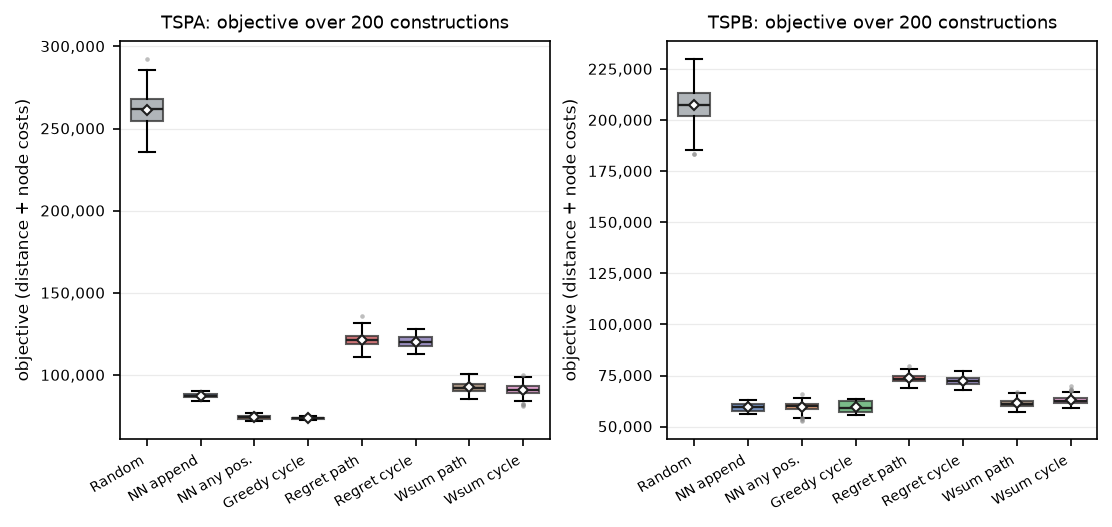

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.3, 3.4), layout="constrained")

for ax, (name, grp) in zip(axes, runs.groupby("instance", sort=False)):
    data = [grp.loc[grp.method == m, "objective"].to_numpy() for m in METHODS]
    bp = ax.boxplot(
        data, tick_labels=[SHORT[m] for m in METHODS], widths=0.6,
        patch_artist=True, showmeans=True,
        medianprops=dict(color="#1f1f1f", lw=1.1),
        meanprops=dict(marker="D", markerfacecolor="white",
                       markeredgecolor="#1f1f1f", markersize=3.5),
        flierprops=dict(marker="o", markersize=2.2, markerfacecolor="#8a8a8a",
                        markeredgecolor="none", alpha=0.55),
    )
    for patch, m in zip(bp["boxes"], METHODS):
        patch.set_facecolor(COLORS[m])
        patch.set_alpha(0.78)
        patch.set_edgecolor("#333333")
    ax.set_title(f"{name}: objective over {RUNS} constructions", fontsize=8.5)
    ax.set_ylabel("objective (distance + node costs)", fontsize=8)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.grid(axis="y", alpha=0.25, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_xticklabels([SHORT[m] for m in METHODS], rotation=30, ha="right",
                       fontsize=6.5)
    ax.tick_params(axis="y", labelsize=7)

fig.savefig(FIG / "distributions.png", bbox_inches="tight")
plt.show()

Random construction is far behind the greedy methods and has the widest spread. Among the greedy methods the differences are much smaller, so the choice of insertion rule matters more than the starting node.

## 6. Best solutions

Each panel shows the cycle built by one method. Grey dots are nodes that were **not** selected. Selected nodes are drawn with a colour **and** a radius that both encode the node cost (dark purple, small = cheap; yellow, large = expensive). Thin arrows show the direction of travel along the cycle.

In [6]:
CMAP = plt.get_cmap("viridis")

def load_tour(name, method):
    row = tours[(tours.instance == name) & (tours.method == method)].iloc[0]
    return np.array([int(v) for v in str(row["tour"]).split()]), row

def draw(ax, name, method, norm, short=True):
    df = COORDS[name]
    tour, row = load_tour(name, method)
    sel = np.zeros(len(df), dtype=bool)
    sel[tour] = True
    x = df.x.to_numpy()
    y = df.y.to_numpy()
    cost = df.cost.to_numpy()

    ax.scatter(x[~sel], y[~sel], s=5, c="#d4d4d4", linewidths=0, zorder=1)
    for i in range(len(tour)):
        a, b = tour[i], tour[(i + 1) % len(tour)]
        ax.annotate("", xy=(x[b], y[b]), xytext=(x[a], y[a]),
                    arrowprops=dict(arrowstyle="-|>", color="#555555", lw=0.42,
                                    shrinkA=2.0, shrinkB=3.0, mutation_scale=5,
                                    alpha=0.75),
                    zorder=2)
    t = (cost[tour] - norm.vmin) / max(1e-9, norm.vmax - norm.vmin)
    ax.scatter(x[tour], y[tour], s=7 + 42 * t, c=cost[tour], cmap=CMAP,
               norm=norm, edgecolors="#1b1b1b", linewidths=0.35, zorder=3)

    label = SHORT[method] if short else LABELS[method]
    ax.set_title(f"{label}\nobjective {nf(row['objective'])}",
                 fontsize=7.2 if short else 7.8, pad=3)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#dcdcdc")

def best_figure(name):
    norm = mpl.colors.Normalize(*COST_RANGE[name])
    ncol = 4
    nrow = (len(METHODS) + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(7.3, 2.05 * nrow),
                             layout="constrained")
    axes = np.atleast_1d(axes).ravel()
    for ax, method in zip(axes, METHODS):
        draw(ax, name, method, norm)
    for ax in axes[len(METHODS):]:
        ax.axis("off")
    fig.suptitle(f"{name}: best solution found by each method", fontsize=10)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=list(axes), fraction=0.022, pad=0.015)
    cb.set_label("node cost", fontsize=7.5)
    cb.ax.tick_params(labelsize=6.5)
    fig.savefig(FIG / f"best_{name}.png", bbox_inches="tight")
    plt.show()

    for method in METHODS:
        single, ax = plt.subplots(figsize=(7.3, 4.4), layout="constrained")
        draw(ax, name, method, norm, short=False)
        single.savefig(FIG / f"best_{name}_{method}.png", bbox_inches="tight")
        plt.close(single)

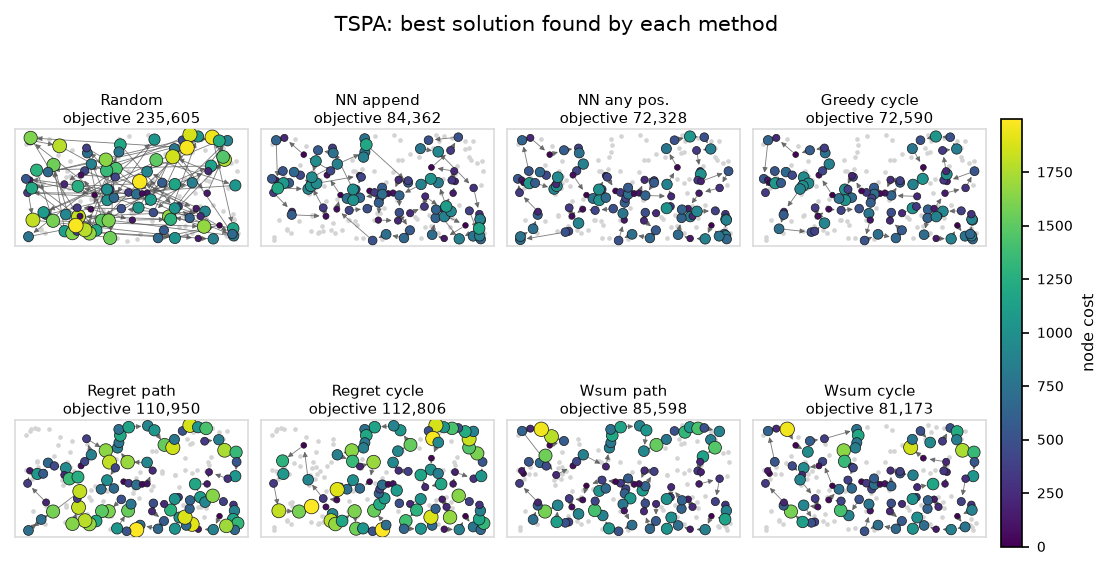

In [7]:
best_figure("TSPA")

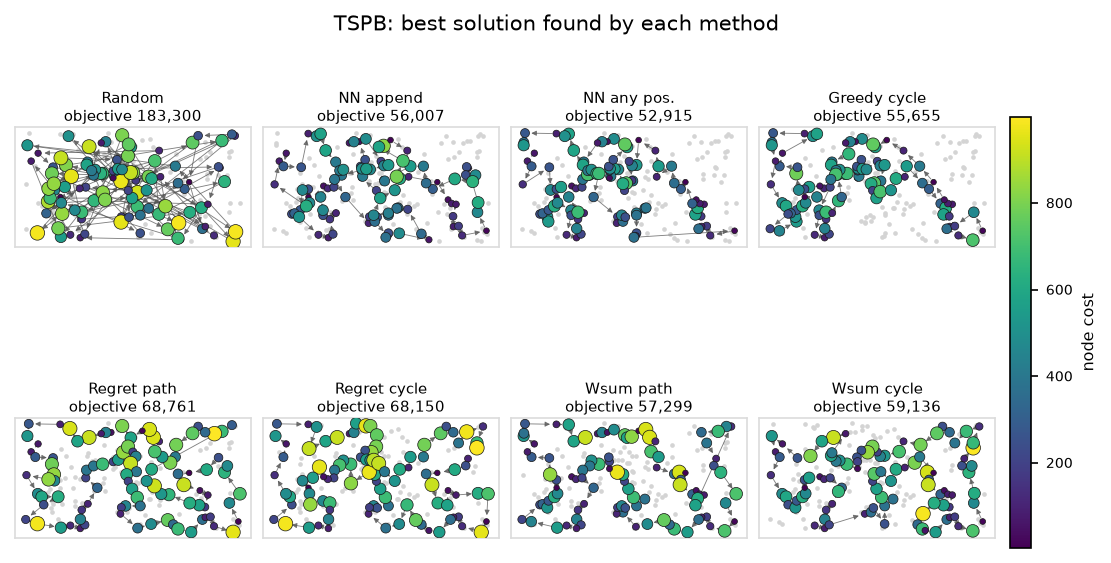

In [8]:
best_figure("TSPB")

## 7. Best solutions as node lists

All indices are **0-based**; the list is the cycle order and the closing arc runs from the last node back to the first one. For spreadsheet use, `results/best_tours_columns.csv` stores the same sixteen tours as columns: every column contains 100 node indices, one per row, so it can be copied directly into Excel without reformatting.

The best solutions below are given in 0-based order and are formatted for the Excel solution checker (`results/best_tours_columns.csv` can be pasted directly). Every stored solution is also independently re-evaluated by the engine's `evaluate()` routine, which recomputes distance, node costs and objective and rejects any mismatch; the external Excel checker had not been run when this report was generated.

In [9]:
for name in INSTANCES:
    print(name)
    for method in METHODS:
        _, row = load_tour(name, method)
        idx = str(row["tour"]).split()
        print(f"\n{LABELS[method]} — objective {nf(row['objective'])} "
              f"(distance {nf(row['distance'])}, costs {nf(row['costs'])}), "
              f"first node {int(row['first_node'])}:")
        for i in range(0, len(idx), 16):
            print("  " + " ".join(idx[i:i + 16]))
    print()

TSPA

Random — objective 235,605 (distance 143,298, costs 92,307), first node 40:
  40 113 74 96 71 102 31 137 51 22 92 66 171 32 127 194
  143 15 37 144 193 161 85 41 136 108 29 75 13 155 79 76
  89 45 30 10 149 180 154 185 35 133 129 70 132 16 106 151
  176 156 116 188 57 64 2 111 107 192 158 163 179 36 59 82
  120 124 162 54 183 5 72 55 84 197 196 157 153 186 99 168
  177 18 4 123 119 166 112 141 135 65 187 198 1 109 93 46
  17 95 195 199

NN (append at end) — objective 84,362 (distance 31,319, costs 53,043), first node 54:
  54 9 33 36 177 67 144 53 135 58 134 176 174 106 89 107
  57 182 151 93 50 3 1 164 178 29 136 186 184 47 159 130
  153 78 88 193 170 146 75 64 150 42 113 43 85 142 8 131
  84 158 192 181 114 141 180 132 76 80 48 31 63 149 168 97
  127 187 30 123 152 108 60 116 49 11 119 160 83 90 51 16
  35 87 45 140 52 179 185 28 102 156 157 71 91 38 100 4
  112 139 115 5

NN (any position) — objective 72,328 (distance 21,816, costs 50,512), first node 104:
  104 129 69 127 97 

## 8. The weighted-sum criterion: weights

The weighted sum mixes two quantities measured on different scales, so before choosing weights it is worth looking at the data. The objective adds node costs and travel distances; the table below compares their typical magnitude in each instance.

In [10]:
scale_rows = []
for name in INSTANCES:
    df = COORDS[name]
    x = df.x.to_numpy()
    y = df.y.to_numpy()
    D = np.floor(np.hypot(x[:, None] - x[None, :], y[:, None] - y[None, :]) + 0.5)
    iu = np.triu_indices(len(df), 1)
    scale_rows.append({
        "Instance": name,
        "Mean node cost": df.cost.mean(),
        "Mean distance": D[iu].mean(),
        "cost / distance": df.cost.mean() / D[iu].mean(),
    })
scale = pd.DataFrame(scale_rows).set_index("Instance")
display(scale.style.format({
    "Mean node cost": "{:,.0f}", "Mean distance": "{:,.0f}",
    "cost / distance": "{:.2f}"}))

,Mean node cost,Mean distance,cost / distance
Instance,,,
TSPA,971,"1,645",0.59
TSPB,519,"1,548",0.34


Node costs and distances are the same order of magnitude (the mean cost is roughly a third to two thirds of the mean distance), and the insertion delta already combines one cost term with one or two distance terms, so the best-change part keeps both halves of the objective balanced by itself. The min–max normalisation in `WEIGHTED_SUM` removes the remaining scale difference between the regret gap and the best change. Because both parts of the objective are already represented inside the best-change term, one would expect the best change to deserve at least as much weight as the regret; the sweep below tests this, including the two endpoints that reproduce the Laboratory-1 methods.

In [11]:
sweep_pairs = [(1.0, 0.0), (0.7, 0.3), (0.5, 0.5), (0.3, 0.7), (0.0, 1.0)]
rows = []
for wr, wb in sweep_pairs:
    out = RES / "sweep" / f"wr{wr:.1f}_wb{wb:.1f}"
    subprocess.run(
        [str(ROOT / "tsp_solver"), "--seed", str(SEED), "--runs", str(RUNS),
         "--wr", str(wr), "--wb", str(wb), "--out", str(out), "--lab", "2"],
        cwd=ROOT, capture_output=True, text=True, check=True)
    s = pd.read_csv(out / "summary.csv")
    for name in INSTANCES:
        for m in ("weighted_path", "weighted_cycle"):
            r = s[(s.instance == name) & (s.method == m)].iloc[0]
            rows.append({"wr": wr, "wb": wb, "instance": name, "method": m,
                         "average": r["average"], "best": r["best"]})
sweep = pd.DataFrame(rows)

piv = sweep.pivot_table(index=["wr", "wb"], columns=["instance", "method"],
                        values="average")
piv.columns = piv.columns.set_names(["Instance", "Method"])
piv = piv.rename(columns={m: SHORT[m] for m in ("weighted_path", "weighted_cycle")},
                 level=1)
display(piv.style.format("{:,.1f}").background_gradient(cmap="RdYlGn_r", axis=1))

The `wb = 1` row reproduces the extended nearest neighbour (open path) and the greedy cycle (closed cycle) exactly, and `wb = 0` is pure regret. The averages are **not** monotone in the weights. On TSPA the best value is at the pure best-change endpoint (73,793 for the closed-cycle base) and every regret component makes it worse. On TSPB a small regret weight helps: `wr = 0.3, wb = 0.7` gives the best averages of the whole sweep (58,498 closed-cycle and 55,513 open-path, below the 59,650/59,476 of the pure best-change endpoint). The equal weights used for the main results are therefore a neutral default rather than the optimum — they are dominated on both instances, and the data suggests the best change should dominate. This fits the node-cost scale: TSPB's nodes are relatively cheap (cost/distance 0.34), so its objective is dominated by travel and the regret signal adds useful placement information, whereas TSPA's costlier nodes (0.59) make the pure best-change rule already effective.

## 9. Observations

In [12]:
import textwrap

from IPython.display import Markdown

stats = runs.groupby(["instance", "method"]).agg(
    mean=("objective", "mean"),
    std=("objective", "std"),
    dist=("distance", "mean"),
    cost=("costs", "mean"),
).reset_index()
stats["cv"] = 100.0 * stats["std"] / stats["mean"]

def st(name, method, column):
    row = stats[(stats.instance == name) & (stats.method == method)]
    return row.iloc[0][column]

def pct(a, b):
    return 100.0 * (b - a) / a

def nr(v):
    return f"{round(v):,}"

def leader(name):
    means = {m: st(name, m, "mean") for m in METHODS if m != "random"}
    return min(means, key=means.get), means

items = []

for name in INSTANCES:
    bm, means = leader(name)
    worst_regret = max(st(name, "regret_path", "mean"),
                       st(name, "regret_cycle", "mean"))
    items.append(
        f"{name}: the lowest average objective is produced by {SHORT[bm]} at "
        f"{nr(means[bm])}. The pure 2-regret variants are the weakest non-random family — "
        f"{SHORT['regret_path']} and {SHORT['regret_cycle']} average "
        f"{nr(st(name, 'regret_path', 'mean'))} and {nr(st(name, 'regret_cycle', 'mean'))}, "
        f"about {pct(means[bm], worst_regret):.0f}% above the leader. Since the node cost is "
        f"identical at every position it cancels out of the regret, so pure 2-regret is "
        f"cost-blind and ranks nodes only by the spread of their distance options - the wrong "
        f"signal when the objective also contains node costs."
    )

for name in INSTANCES:
    bm, means = leader(name)
    wp, wc = st(name, "weighted_path", "mean"), st(name, "weighted_cycle", "mean")
    items.append(
        f"Blending the best change back through the weighted sum recovers most of that loss: "
        f"on {name}, {SHORT['weighted_path']} and {SHORT['weighted_cycle']} average {nr(wp)} "
        f"and {nr(wc)}, only {min(pct(means[bm], wp), pct(means[bm], wc)):.1f}–"
        f"{max(pct(means[bm], wp), pct(means[bm], wc)):.1f}% above {SHORT[bm]}. The criterion "
        f"now rewards both a small best change and a large regret, which is exactly the "
        f"trade-off the two Laboratory-1 methods represent at its endpoints."
    )

for name in INSTANCES:
    sub = summary[summary.instance == name]
    b = sub.loc[sub["best"].idxmin()]
    items.append(
        f"The best single solution on {name} is {nr(b['best'])} found by "
        f"{LABELS[b['method']]}."
    )

ms = summary.groupby("method")["time_ms"].mean() / RUNS
items.append(
    "Cost per construction: append-at-end "
    f"{ms['nn_end']:.3f} ms, any-position {ms['nn_all']:.2f} ms, greedy cycle "
    f"{ms['greedy_cycle']:.2f} ms, 2-regret {ms['regret_path']:.2f}–{ms['regret_cycle']:.2f} ms "
    f"and weighted sum {ms['weighted_path']:.2f}–{ms['weighted_cycle']:.2f} ms. The regret "
    "rules keep the full cost of the any-position/greedy-cycle search and add a second-best "
    "scan, so they are the most expensive without being the most accurate."
)

items.append(
    "Random stays a baseline: its objective is several times the greedy values on both "
    "instances, and both its distance and node-cost terms are far worse, so it fails on both "
    "parts of the objective."
)

bullets = "\n".join(
    textwrap.fill(item, width=88, initial_indent="- ", subsequent_indent="  ")
    for item in items
)
display(Markdown(bullets))

- TSPA: the lowest average objective is produced by Greedy cycle at 73,793. The pure
  2-regret variants are the weakest non-random family — Regret path and Regret cycle
  average 121,360 and 120,379, about 64% above the leader. Since the node cost is
  identical at every position it cancels out of the regret, so pure 2-regret is cost-
  blind and ranks nodes only by the spread of their distance options - the wrong signal
  when the objective also contains node costs.
- TSPB: the lowest average objective is produced by NN append at 59,397. The pure
  2-regret variants are the weakest non-random family — Regret path and Regret cycle
  average 73,650 and 72,485, about 24% above the leader. Since the node cost is
  identical at every position it cancels out of the regret, so pure 2-regret is cost-
  blind and ranks nodes only by the spread of their distance options - the wrong signal
  when the objective also contains node costs.
- Blending the best change back through the weighted sum recovers most of that loss: on
  TSPA, Wsum path and Wsum cycle average 92,603 and 91,064, only 23.4–25.5% above Greedy
  cycle. The criterion now rewards both a small best change and a large regret, which is
  exactly the trade-off the two Laboratory-1 methods represent at its endpoints.
- Blending the best change back through the weighted sum recovers most of that loss: on
  TSPB, Wsum path and Wsum cycle average 61,458 and 62,870, only 3.5–5.8% above NN
  append. The criterion now rewards both a small best change and a large regret, which
  is exactly the trade-off the two Laboratory-1 methods represent at its endpoints.
- The best single solution on TSPA is 72,328 found by NN (any position).
- The best single solution on TSPB is 52,915 found by NN (any position).
- Cost per construction: append-at-end 0.045 ms, any-position 1.35 ms, greedy cycle 2.58
  ms, 2-regret 1.53–3.19 ms and weighted sum 1.59–3.22 ms. The regret rules keep the
  full cost of the any-position/greedy-cycle search and add a second-best scan, so they
  are the most expensive without being the most accurate.
- Random stays a baseline: its objective is several times the greedy values on both
  instances, and both its distance and node-cost terms are far worse, so it fails on
  both parts of the objective.

**Discussion.** Keeping the Laboratory-1 constructions as a reference shows that the regret idea does not help in its pure form. Pure 2-regret is the weakest of all non-random methods on both instances: because the node cost cancels out of the regret, the rule is cost-blind and inserts the node with the largest distance spread between its best and second-best option, which favours urgent placement over cheap placement and ends up with worse routes and more expensive node sets. The weighted sum interpolates between pure regret and the Laboratory-1 methods; at equal weights it is clearly better than pure regret but still worse than the greedy methods it generalises. The sweep in Section 8 shows that the equal-weight default is not the optimum: the best change should dominate, and on TSPB a small regret weight (`wr = 0.3`) actually improves on the pure best-change endpoint. Overall the practical conclusion of Laboratory 1 is unchanged — on TSPA the greedy cycle is the most reliable average method, on TSPB append-at-end (and, in the sweep, the `wr = 0.3` weighted sum) trades a longer route for a cheaper node set, and the best single solutions come from the broadest positional search.

## 10. Reproduction

```bash
# 1. Python environment (once)
python3 -m venv .venv
.venv/bin/pip install nbconvert ipykernel matplotlib pandas numpy jupyterlab

# 2. Engine
make

# 3. Execute this notebook, export HTML with report.css and print the PDF
.venv/bin/python tools/render_report.py
```

`run.sh` performs all of these steps and can also be used to rebuild everything from scratch; the notebook can be opened for interactive use with `.venv/bin/jupyter lab`. The engine writes `results/summary.csv`, `results/runs.csv`, `results/best_tours.csv` and `results/best_tours_columns.csv`; this notebook writes the figures to `report/figures/` and the exported report to `report/report.html` and `report/report.pdf`.